In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time
import joblib

from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

import optuna

import json
import joblib
from pathlib import Path


import random
from heapq import nsmallest

In [35]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [37]:
# Fix random state
random_state = 42

In [38]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

#harps.isnull().sum() # No null values


galah = galah[(galah.zmax < 10) ]

apogee = apogee[(apogee.zmax < 10) ]
apogee.shape


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 69449 stars
gr8 contains 1430 stars


In [39]:
def fit_trasform(X):
    #X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    #X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    #X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    #X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)

In [40]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
    "o_h":          r"$[\mathrm{O/H}]$",
    "mg_h":         r"$[\mathrm{Mg/H}]$",
    "si_h":         r"$[\mathrm{Si/H}]$",
    "c_h":          r"$[\mathrm{C/H}]$",
}

In [73]:
import numpy as np
import optuna
import pandas as pd

from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from lightgbm import LGBMRegressor


class AbundancePredictor:

    def __init__(self, apogee_df, harps_df, element, features=None, random_state=42):
        """
        Parameters
        ----------
        apogee_df : pandas.DataFrame
            Training dataset (used for train/validation split and tuning).
        harps_df : pandas.DataFrame
            Independent test dataset.
        element : str
            Target abundance (e.g. 'o_h', 'mg_h', 'si_h', 'c_h').
        features : list, optional
            Input features used for prediction.
        """
        self.apogee_df = apogee_df.copy()
        self.harps_df = harps_df.copy()
        self.element = element
        self.random_state = random_state

        if features is None:
            self.features = [
                'U_lsr', 'V_lsr', 'W_lsr', 'P_gal',
                'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h'
            ]
        else:
            self.features = features

        self.model = None
        self.best_params = None
        self.best_rmse = None
        self.study = None

        self.apogee_el = None
        self.harps_el = None

   

    def prepare_element_data(self, dropna_harps=True):

        cols = self.features + [self.element]

        self.apogee_el = self.apogee_df[cols].copy()
        self.harps_el  = self.harps_df[cols].copy()

        # remove rows where target abundance is missing
        self.apogee_el = self.apogee_el.dropna(subset=[self.element])

        if dropna_harps:
            self.harps_el = self.harps_el.dropna(subset=[self.element])

        return self.apogee_el, self.harps_el

    def split_data(self, test_size=0.1):
        """
        Train/validation split on APOGEE element-specific dataframe.
        """
        df = self.apogee_el if self.apogee_el is not None else self.apogee_df

        X = df[self.features]
        y = df[self.element]

        self.X_train, self.X_val, self.y_train, self.y_val = train_test_split(
            X, y,
            test_size=test_size,
            random_state=self.random_state
        )
        return self.X_train, self.X_val, self.y_train, self.y_val

    def split_X_y_features(self):
        """
        Return X/y for APOGEE and HARPS using prepared element-specific data if available.
        """
        apogee_data = self.apogee_el if self.apogee_el is not None else self.apogee_df
        harps_data = self.harps_el if self.harps_el is not None else self.harps_df

        self.X = apogee_data[self.features]
        self.y = apogee_data[self.element]
        self.X_harps = harps_data[self.features]
        self.y_harps = harps_data[self.element]

        return self.X, self.y, self.features, self.X_harps, self.y_harps

    @staticmethod
    def rmse(y_true, y_pred):
        return float(np.sqrt(mean_squared_error(y_true, y_pred)))

    def cv_rmse(self, model, X, y, cv):
        scores = []

        for tr, te in cv.split(X, y):
            m = clone(model)
            m.fit(X.iloc[tr], y.iloc[tr])
            pred = m.predict(X.iloc[te])
            scores.append(self.rmse(y.iloc[te], pred))

        return float(np.mean(scores)), float(np.std(scores))

    def objective_lgbm(self, trial, X, y, cv):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),

            "num_leaves": trial.suggest_int("num_leaves", 16, 256),
            "max_depth": trial.suggest_int("max_depth", -1, 16),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 200),

            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),

            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 50.0, log=True),

            "random_state": self.random_state,
            "n_jobs": -1,
            "verbosity": -1,
        }

        model = LGBMRegressor(**params)
        mean_rmse, _ = self.cv_rmse(model, X, y, cv)
        return mean_rmse

    def tune_lgbm(self, n_trials=50, n_splits=5, study_name=None, show_progress_bar=False):
        """
        Tune LightGBM hyperparameters on APOGEE using CV.
        """
        if self.apogee_el is None:
            self.prepare_element_data()

        X, y, _, _, _ = self.split_X_y_features()

        cv = KFold(n_splits=n_splits, shuffle=True, random_state=self.random_state)

        if study_name is None:
            study_name = f"LGBM_{self.element}"

        study = optuna.create_study(direction="minimize", study_name=study_name)

        study.optimize(
            lambda trial: self.objective_lgbm(trial, X, y, cv),
            n_trials=n_trials,
            show_progress_bar=show_progress_bar
        )

        self.study = study
        self.best_params = study.best_params
        self.best_rmse = study.best_value

        return self.best_params, self.best_rmse

    def fit_best_lgbm(self):
        """
        Fit the best-tuned LightGBM on the full APOGEE sample.
        """
        if self.best_params is None:
            raise ValueError("Run tune_lgbm() first.")

        if self.apogee_el is None:
            self.prepare_element_data()

        X = self.apogee_el[self.features]
        y = self.apogee_el[self.element]

        self.model = LGBMRegressor(
            **self.best_params,
            random_state=self.random_state,
            n_jobs=-1,
            verbosity=-1
        )
        self.model.fit(X, y)
        return self.model

    def evaluate_on_harps(self):
        """
        Evaluate fitted model on independent HARPS test sample.
        """
        if self.model is None:
            raise ValueError("No fitted model found. Run fit_best_lgbm() first.")

        if self.harps_el is None:
            self.prepare_element_data()

        X_test = self.harps_el[self.features]
        y_test = self.harps_el[self.element]

        pred = self.model.predict(X_test)

        rmse = self.rmse(y_test, pred)
        mae = float(np.mean(np.abs(y_test - pred)))
        r2 = float(self.model.score(X_test, y_test))

        return {
            "element": self.element,
            "rmse_harps": rmse,
            "mae_harps": mae,
            "r2_harps": r2,
            "n_harps": len(y_test)
        }
    
    def save_best_params(self, outdir="./models"):
        """
        Save best hyperparameters to a JSON file.
        """
        if self.best_params is None:
            raise ValueError("No best parameters found. Run tune_lgbm() first.")

        outdir = Path(outdir)
        outdir.mkdir(parents=True, exist_ok=True)

        payload = {
            "element": self.element,
            "features": self.features,
            "best_rmse_cv": self.best_rmse,
            "best_params": self.best_params,
            "random_state": self.random_state,
        }

        outfile = outdir / f"lgbm_best_params_{self.element}.json"

        with open(outfile, "w") as f:
            json.dump(payload, f, indent=4)

        return outfile


    def load_best_params(self, filepath):
        """
        Load best hyperparameters from a JSON file.
        """
        filepath = Path(filepath)

        with open(filepath, "r") as f:
            payload = json.load(f)

        self.best_params = payload["best_params"]
        self.best_rmse = payload.get("best_rmse_cv", None)

        return self.best_params


    def fit_full_apogee(self):
        """
        Fit the best LightGBM model on the full APOGEE dataset for the selected element.
        """
        if self.best_params is None:
            raise ValueError("No best parameters found. Run tune_lgbm() or load_best_params() first.")

        if self.apogee_el is None:
            self.prepare_element_data()

        X_full = self.apogee_el[self.features]
        y_full = self.apogee_el[self.element]

        self.model = LGBMRegressor(
            **self.best_params,
            random_state=self.random_state,
            n_jobs=-1,
            verbosity=-1
        )

        self.model.fit(X_full, y_full)

        return self.model


    def save_model(self, outdir="./models"):
        """
        Save the trained model to disk.
        """
        if self.model is None:
            raise ValueError("No trained model found. Run fit_full_apogee() first.")

        outdir = Path(outdir)
        outdir.mkdir(parents=True, exist_ok=True)

        outfile = outdir / f"lgbm_model_{self.element}.joblib"
        joblib.dump(self.model, outfile)

        return outfile


    def load_model(self, filepath):
        """
        Load a trained model from disk.
        """
        filepath = Path(filepath)
        self.model = joblib.load(filepath)
        return self.model
    
    def predict_apogee_holdout(self, test_size=0.2):
        """
        Split APOGEE into train/test, train with best hyperparameters, predict test set.
        """
        if self.best_params is None:
            raise ValueError("No best parameters found. Run tuning or load parameters first.")

        if self.apogee_el is None:
            self.prepare_element_data()

        X = self.apogee_el[self.features]
        y = self.apogee_el[self.element]

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=self.random_state
        )

        model = LGBMRegressor(
            **self.best_params,
            random_state=self.random_state,
            n_jobs=-1,
            verbosity=-1
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        return X_test, y_test, y_pred

    def predict_harps(self):
        """
        Predict HARPS using the model already trained on full APOGEE.
        """
        if self.model is None:
            raise ValueError("No trained full-APOGEE model found. Run fit_full_apogee() or load_model().")

        if self.harps_el is None:
            self.prepare_element_data()

        X = self.harps_el[self.features]
        y = self.harps_el[self.element]
        y_pred = self.model.predict(X)

        return X, y, y_pred

    def get_pretty_elfe_label(self, pretty_labels):
        target_label = pretty_labels.get(self.element, self.element)
        if isinstance(target_label, str):
            return target_label.replace("/H", "/Fe")
        return self.element


    def plot_abundance_prediction_panels(
        self,
        X,
        y_true,
        y_pred,
        sample_name="APOGEE",
        color="tab:blue",
        save_path=None,
        pretty_labels=None,
        s_true=40,
        s_pred=40,
        alpha_true=0.4,
        alpha_pred=0.7
    ):
        """
        Two-panel plot:
        left  : [El/Fe] vs [Fe/H] (true in grey, predicted in color)
        right : residuals (true - pred) vs true [El/H]

        Also shows RMSE for model and base predictor where [El/H] = [Fe/H].
        """

        feh = np.asarray(X["fe_h"]).astype(float)
        y_true = np.asarray(y_true).astype(float)
        y_pred = np.asarray(y_pred).astype(float)

        # base predictor: assume [El/H] = [Fe/H]
        y_base = feh.copy()

        # convert to [El/Fe]
        elfe_true = y_true - feh
        elfe_pred = y_pred - feh

        # residuals in [El/H]
        resid_model = y_true - y_pred
        resid_base = y_true - y_base

        rmse_model = self.rmse(y_true, y_pred)
        rmse_base = self.rmse(y_true, y_base)

        # labels
        if pretty_labels is None:
            xlab = r"$[\mathrm{Fe/H}]$"
            ylab_left = f"[{self.element}]"
        else:
            xlab = pretty_labels.get("fe_h", r"$[\mathrm{Fe/H}]$")
            target_label = pretty_labels.get(self.element, self.element)

            # convert [X/H] label -> [X/Fe] label for display
            if target_label.startswith(r"$[\mathrm{") and target_label.endswith(r"/H}]$"):
                #ylab_left = target_label.replace("/H", "/Fe")
                ylab_left = self.get_pretty_elfe_label(pretty_labels)
            else:
                ylab_left = rf"$[\mathrm{{{self.element.replace('_h','').upper()}/Fe}}]$"

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

        # -------------------------
        # Left panel: [El/Fe] vs [Fe/H]
        # -------------------------
        ax = axes[0]

        ax.scatter(
            feh, elfe_true,
            s=s_true, color="lightgray", alpha=alpha_true,
            edgecolor="none", label="True"
        )
        ax.scatter(
            feh, elfe_pred,
            s=s_pred, color=color, alpha=alpha_pred,
            edgecolor="none", label="Predicted"
        )

        ax.axhline(0.0, ls="--", lw=1.0, color="black")

        ax.set_xlabel(xlab)
        ax.set_ylabel(ylab_left)
        ax.set_title(sample_name)



        #ax.legend(frameon=False, loc="best")

        # -------------------------
        # Right panel: residuals vs true [El/H]
        # -------------------------
        ax = axes[1]

        # limit sample in residual panel by metallicity
        feh = np.asarray(X["fe_h"]).astype(float)
        mask = (feh > -0.8) & (feh < 0.35)

        y_true_res = y_true[mask]
        resid_res = resid_model[mask]

        ax.scatter(
            y_true_res, resid_res,
            s=s_pred, color=color, alpha=alpha_pred,
            edgecolor="none"
        )

        ax.axhline(0.0, ls="--", lw=1.0, color="black")

        ax.set_xlabel(f"True {pretty_labels.get(self.element, self.element) if pretty_labels else self.element}")
        ax.set_ylabel(
            f"Residual ({pretty_labels.get(self.element, self.element) if pretty_labels else self.element}"
            r"$_{\rm true}$"
            f" - {pretty_labels.get(self.element, self.element) if pretty_labels else self.element}"
            r"$_{\rm pred}$)"
        )
        ax.set_title("Residuals")

        ax.text(
            0.03, 0.97,
            rf"$\mathrm{{RMSE}}_{{\rm model}} = {rmse_model:.3f}$ dex" "\n"
            rf"$\mathrm{{RMSE}}_{{\rm [Fe/H]}} = {rmse_base:.3f}$ dex",
            transform=ax.transAxes,
            va="top"
        )

        if save_path is not None:
            plt.savefig(save_path, dpi=300, bbox_inches="tight")

        plt.show()

        return {
            "rmse_model": rmse_model,
            "rmse_base": rmse_base
        }

In [43]:
elements = ['o_h', 'mg_h', 'si_h', 'c_h']

all_results = {}

for el in elements:
    print(f"\n===== {el} =====")

    predictor = AbundancePredictor(
        apogee_df=apogee,
        harps_df=harps,
        element=el,
        random_state=42
    )

    # prepare element-specific data
    predictor.prepare_element_data()

    # tune on APOGEE only
    best_params, best_rmse_cv = predictor.tune_lgbm(
        n_trials=20,
        n_splits=3,
        study_name=f"LGBM_{el}"
    )

    # save best hyperparameters
    params_file = predictor.save_best_params(outdir="./models")
    print("Saved params to:", params_file)
    print("Best CV RMSE:", best_rmse_cv)

    # fit best model on full APOGEE
    predictor.fit_full_apogee()

    # save trained model
    model_file = predictor.save_model(outdir="./models")
    print("Saved model to:", model_file)

    # final independent test on HARPS
    harps_scores = predictor.evaluate_on_harps()
    print("HARPS RMSE:", harps_scores["rmse_harps"])

    # store everything
    all_results[el] = {
        "best_params": best_params,
        "best_rmse_cv": best_rmse_cv,
        "params_file": str(params_file),
        "model_file": str(model_file),
        "rmse_harps": harps_scores["rmse_harps"],
        "mae_harps": harps_scores["mae_harps"],
        "r2_harps": harps_scores["r2_harps"],
        "n_harps": harps_scores["n_harps"],
    }

[I 2026-03-13 13:44:49,266] A new study created in memory with name: LGBM_o_h



===== o_h =====


[I 2026-03-13 13:44:49,860] Trial 0 finished with value: 0.055422298527261764 and parameters: {'n_estimators': 174, 'learning_rate': 0.1875460956602635, 'num_leaves': 162, 'max_depth': 3, 'min_child_samples': 191, 'subsample': 0.8527138681638669, 'colsample_bytree': 0.5492510535030836, 'reg_alpha': 0.051276145582911055, 'reg_lambda': 0.00014911259562653178}. Best is trial 0 with value: 0.055422298527261764.
[I 2026-03-13 13:45:19,549] Trial 1 finished with value: 0.057195479441354724 and parameters: {'n_estimators': 516, 'learning_rate': 0.009562316234022665, 'num_leaves': 231, 'max_depth': 11, 'min_child_samples': 153, 'subsample': 0.646515638305405, 'colsample_bytree': 0.5522784186600318, 'reg_alpha': 1.5214060718793263e-08, 'reg_lambda': 2.214527281347836e-07}. Best is trial 0 with value: 0.055422298527261764.
[I 2026-03-13 13:45:30,425] Trial 2 finished with value: 0.055531228228825134 and parameters: {'n_estimators': 857, 'learning_rate': 0.008519290860888179, 'num_leaves': 16, 'm

Saved params to: models/lgbm_best_params_o_h.json
Best CV RMSE: 0.054823104072004414


[I 2026-03-13 13:49:53,873] A new study created in memory with name: LGBM_mg_h


Saved model to: models/lgbm_model_o_h.joblib
HARPS RMSE: 0.09833291843726794

===== mg_h =====


... (6 outputs left out)

[I 2026-03-13 14:03:01,601] A new study created in memory with name: LGBM_c_h


Saved model to: models/lgbm_model_si_h.joblib
HARPS RMSE: 0.04281642993788531

===== c_h =====


[I 2026-03-13 14:03:17,548] Trial 0 finished with value: 0.08303831587643527 and parameters: {'n_estimators': 410, 'learning_rate': 0.1936569700700926, 'num_leaves': 68, 'max_depth': 13, 'min_child_samples': 16, 'subsample': 0.714846081789926, 'colsample_bytree': 0.9429420853022225, 'reg_alpha': 8.262693332323005e-06, 'reg_lambda': 4.076124551887345e-05}. Best is trial 0 with value: 0.08303831587643527.
[I 2026-03-13 14:03:38,651] Trial 1 finished with value: 0.08150953053396931 and parameters: {'n_estimators': 476, 'learning_rate': 0.009048664539069738, 'num_leaves': 111, 'max_depth': 8, 'min_child_samples': 29, 'subsample': 0.9306297886620525, 'colsample_bytree': 0.651589687739543, 'reg_alpha': 2.7062474474336207, 'reg_lambda': 2.0868472722200833e-06}. Best is trial 1 with value: 0.08150953053396931.
[I 2026-03-13 14:03:39,792] Trial 2 finished with value: 0.0801950276434308 and parameters: {'n_estimators': 230, 'learning_rate': 0.07396337983918098, 'num_leaves': 67, 'max_depth': 2, 

Saved params to: models/lgbm_best_params_c_h.json
Best CV RMSE: 0.07878688448478949
Saved model to: models/lgbm_model_c_h.joblib
HARPS RMSE: 0.09674736587271747


In [51]:
results_df = pd.DataFrame.from_dict(all_results, orient="index").reset_index()
results_df = results_df.rename(columns={"index": "element"})

results_df = results_df[
    [
        "element",
        "best_rmse_cv",
        "rmse_harps",
        "mae_harps",
        "r2_harps",
        "n_harps",
        "params_file",
        "model_file",
    ]
]

print(results_df)

  element  best_rmse_cv  rmse_harps  mae_harps  r2_harps  n_harps  \
0     o_h      0.054823    0.098333   0.073310  0.587080      232   
1    mg_h      0.049392    0.070393   0.052753  0.885526      798   
2    si_h      0.036646    0.042816   0.031246  0.963346      798   
3     c_h      0.078787    0.096747   0.077709  0.803417      627   

                         params_file                     model_file  
0   models/lgbm_best_params_o_h.json   models/lgbm_model_o_h.joblib  
1  models/lgbm_best_params_mg_h.json  models/lgbm_model_mg_h.joblib  
2  models/lgbm_best_params_si_h.json  models/lgbm_model_si_h.joblib  
3   models/lgbm_best_params_c_h.json   models/lgbm_model_c_h.joblib  



===== o_h =====


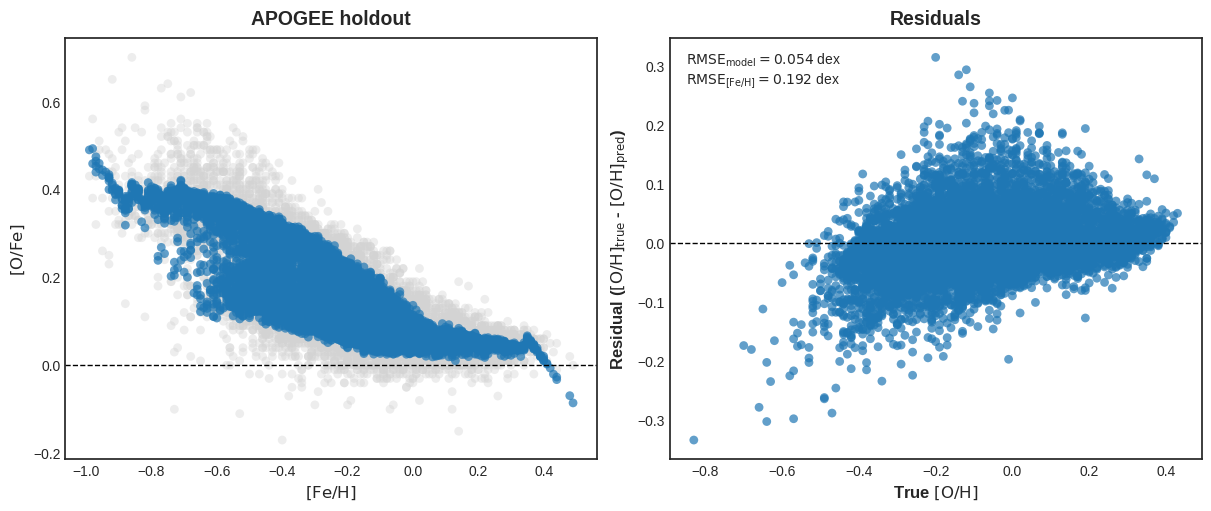

APOGEE holdout: RMSE(model) = 0.054, RMSE(base) = 0.192


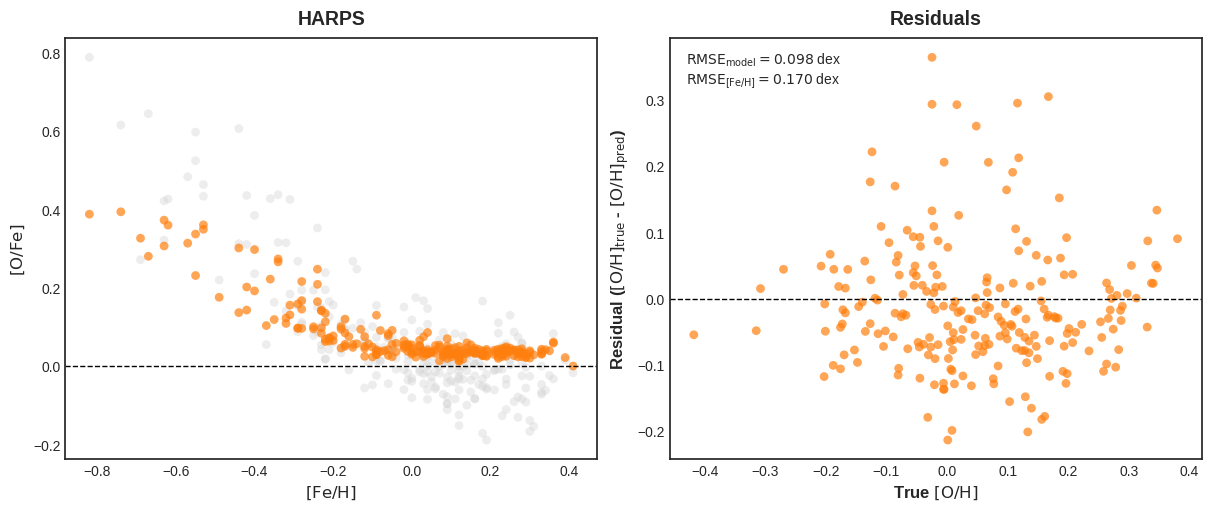

HARPS: RMSE(model) = 0.098, RMSE(base) = 0.170

===== mg_h =====


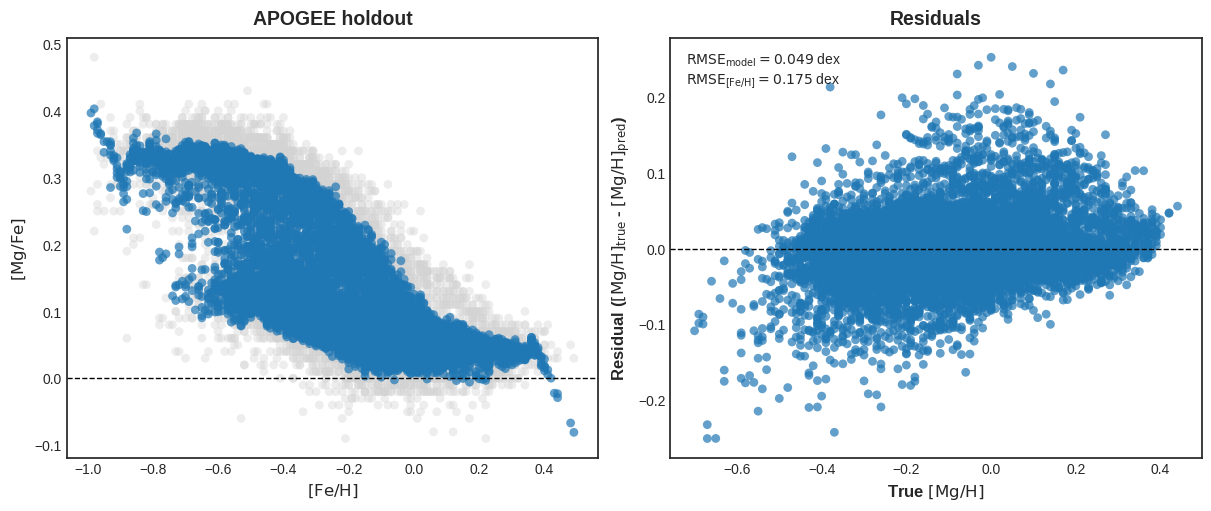

APOGEE holdout: RMSE(model) = 0.049, RMSE(base) = 0.175


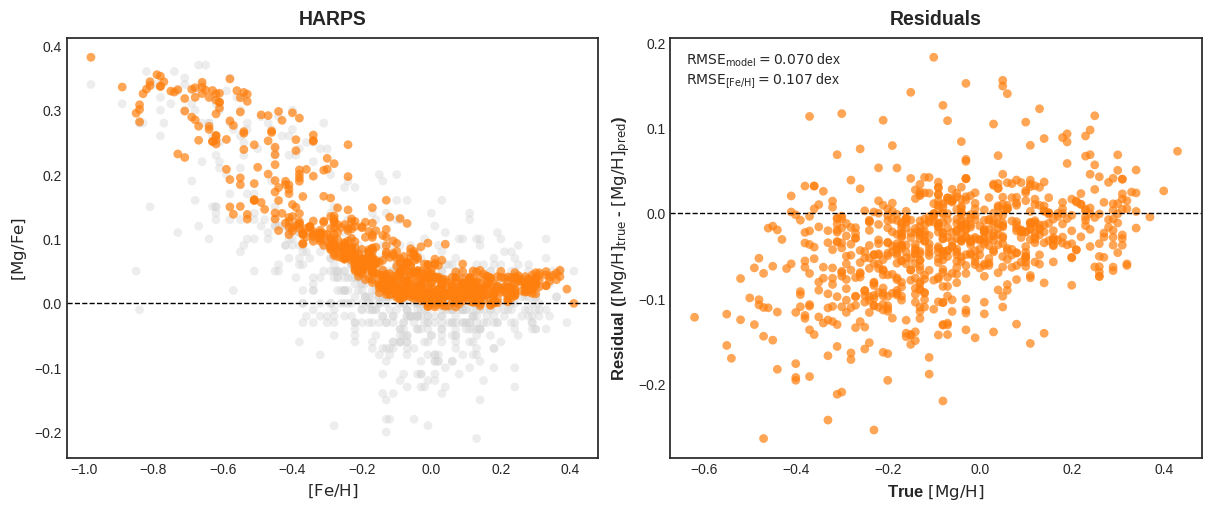

HARPS: RMSE(model) = 0.070, RMSE(base) = 0.107

===== si_h =====


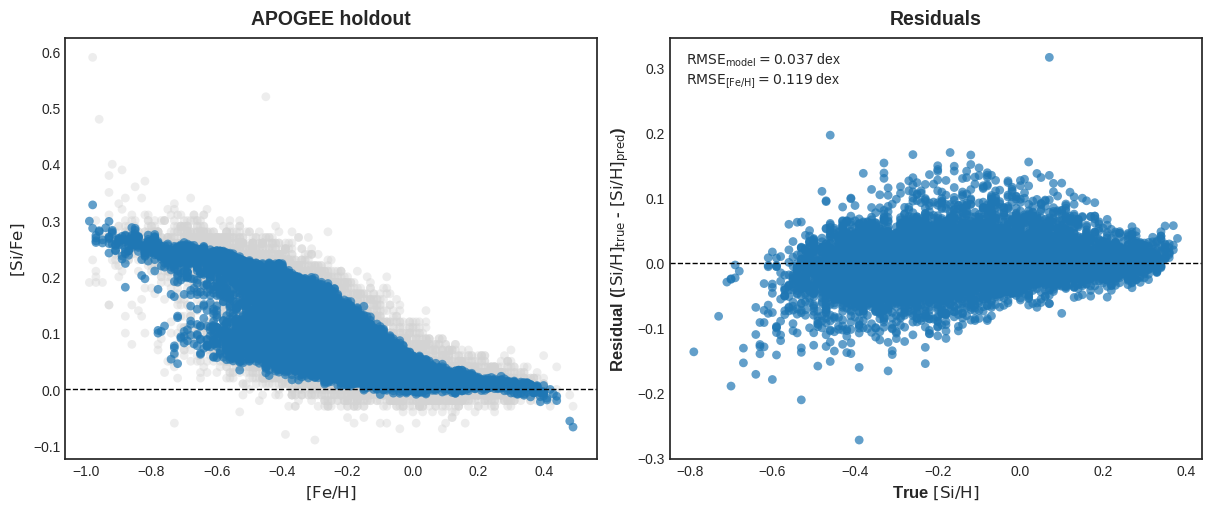

APOGEE holdout: RMSE(model) = 0.037, RMSE(base) = 0.119


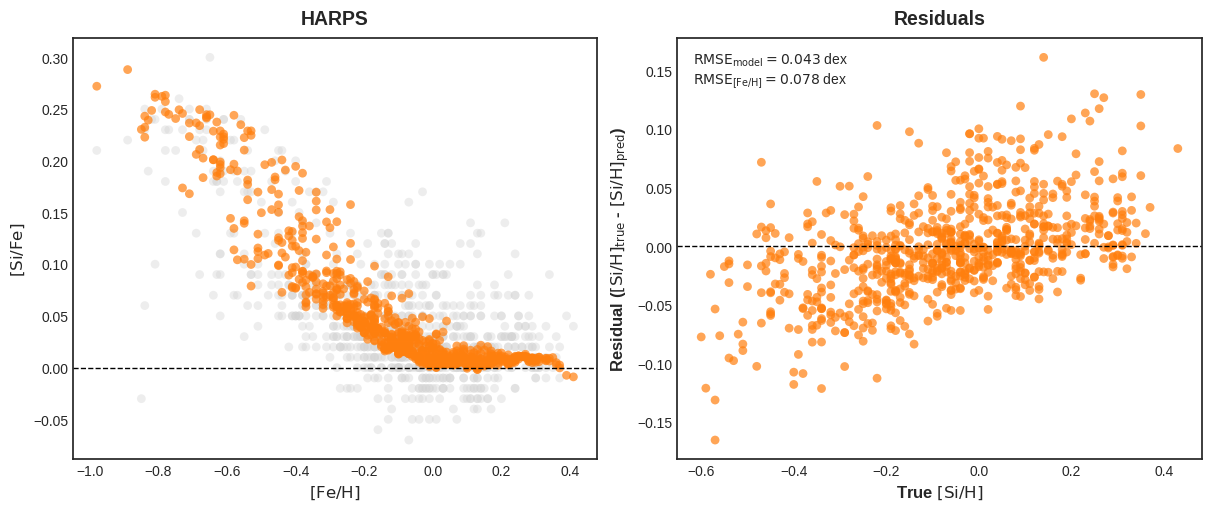

HARPS: RMSE(model) = 0.043, RMSE(base) = 0.078

===== c_h =====


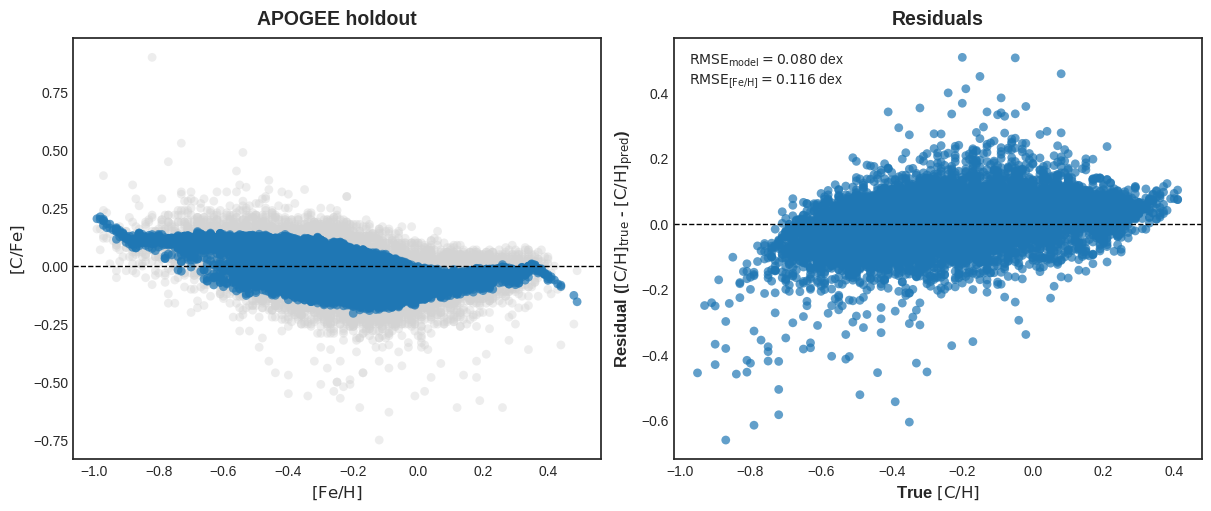

APOGEE holdout: RMSE(model) = 0.080, RMSE(base) = 0.116


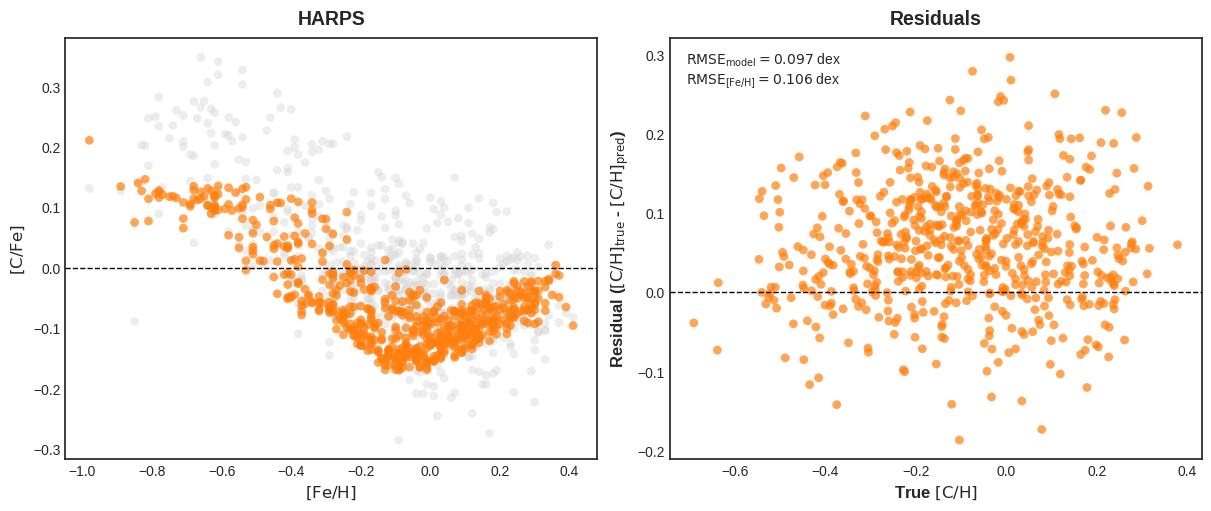

HARPS: RMSE(model) = 0.097, RMSE(base) = 0.106


In [76]:
harps_restricted = harps[(harps.fe_h > -1) & (harps.fe_h < 0.6)]


from pathlib import Path

elements = ["o_h", "mg_h", "si_h", "c_h"]
colors = {
    "o_h": "tab:blue",
    "mg_h": "tab:green",
    "si_h": "tab:orange",
    "c_h": "tab:red",
}

color_list_2 = ["#1f77b4", "#ff7f0e"] 

params_dir = Path("./models")
fig_dir = Path("./figures")
fig_dir.mkdir(parents=True, exist_ok=True)

for el in elements:
    print(f"\n===== {el} =====")

    predictor = AbundancePredictor(
        apogee_df=apogee,
        harps_df=harps_restricted,
        element=el,
        random_state=42
    )
    predictor.prepare_element_data()

    # load best tuned hyperparameters
    predictor.load_best_params(params_dir / f"lgbm_best_params_{el}.json")

    # -----------------------------
    # 1. APOGEE holdout evaluation
    # -----------------------------
    X_test, y_test, y_pred = predictor.predict_apogee_holdout(test_size=0.2)



    scores_apogee = predictor.plot_abundance_prediction_panels(
        X=X_test,
        y_true=y_test,
        y_pred=y_pred,
        sample_name="APOGEE holdout",
        color="#1f77b4",
        save_path=fig_dir / f"{el}_apogee_holdout.png",
        pretty_labels=PRETTY_LABELS
    )

    print(
        f"APOGEE holdout: "
        f"RMSE(model) = {scores_apogee['rmse_model']:.3f}, "
        f"RMSE(base) = {scores_apogee['rmse_base']:.3f}"
    )

    # -----------------------------------------
    # 2. Train on full APOGEE and save the model
    # -----------------------------------------
    predictor.fit_full_apogee()
    #model_file = predictor.save_model("./models")
    #print("Saved full APOGEE model to:", model_file)

    # -----------------------------
    # 3. HARPS blind test
    # -----------------------------
    X_harps, y_harps, y_pred_harps = predictor.predict_harps()

    scores_harps = predictor.plot_abundance_prediction_panels(
        X=X_harps,
        y_true=y_harps,
        y_pred=y_pred_harps,
        sample_name="HARPS",
        color='#ff7f0e',
        save_path=fig_dir / f"{el}_harps.png",
        pretty_labels=PRETTY_LABELS
    )

    print(
        f"HARPS: "
        f"RMSE(model) = {scores_harps['rmse_model']:.3f}, "
        f"RMSE(base) = {scores_harps['rmse_base']:.3f}"
    )

In [45]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    #plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def two_panel_pred_resid_with_mean(
    y_true,
    y_pred,
    model_name="Model",
    sample_name="Sample",
    gridsize=20,
    bins=100,
    cmap="viridis",
    save_path=None,
    add_colorbar=True
):
    """
    Two-panel figure:
      (a) y_pred vs y_true with 1:1 line and mean-predictor reference
      (b) residuals vs y_true with median trend and ±1σ envelope
    Includes metrics for model and mean predictor.

    y_true, y_pred: arrays or Series in dex.
    """

    y_true = np.asarray(y_true).astype(float)
    y_pred = np.asarray(y_pred).astype(float)

    # Mean predictor
    y_mean = np.full_like(y_true, np.mean(y_true))

    # Metrics
    resid_model = y_true - y_pred
    resid_mean  = y_true - y_mean

    rmse_model = np.sqrt(np.mean(resid_model**2))
    rmse_mean  = np.sqrt(np.mean(resid_mean**2))

    sigma_y = np.std(y_true)
    r2_model = 1.0 - (rmse_model**2) / (sigma_y**2) if sigma_y > 0 else np.nan
    r2_mean  = 1.0 - (rmse_mean**2) / (sigma_y**2) if sigma_y > 0 else np.nan  # ~0 by construction

    # Limits (consistent)
    pad = 0.03 * (y_true.max() - y_true.min() + 1e-9)
    x_min, x_max = y_true.min() - pad, y_true.max() + pad
    y_min, y_max = min(y_pred.min(), y_true.min()) - pad, max(y_pred.max(), y_true.max()) + pad

    # Residual y-lims symmetric for aesthetics
    rmax = np.nanpercentile(np.abs(resid_model), 99)
    rmax = max(rmax, np.nanpercentile(np.abs(resid_mean), 99))
    r_lim = 1.05 * rmax

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

    # -------------------------
    # (a) Predicted vs True
    # -------------------------
    ax = axes[0]
    hb0 = ax.hexbin(y_true, y_pred, gridsize=gridsize, cmap=cmap, mincnt=5)
    ax.plot([x_min, x_max], [x_min, x_max], ls="--", lw=1.2, color="gray", label="1:1")

    # mean predictor shown as horizontal line at <y_true>
    ax.axhline(np.mean(y_true), ls=":", lw=1.5, color="black", label=r"Mean predictor ($\langle y\rangle$)")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Predicted $\mathrm{[Fe/H]}$ [dex]")
    ax.set_title(f"{model_name} — {sample_name}")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n" rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex" "\n" rf"Mean $R^2={r2_mean:.3f}$",
        transform=ax.transAxes,
        ha="right", va="bottom"
    )

    ax.legend(frameon=False, loc="lower right")

    # -------------------------
    # (b) Residuals vs True
    # -------------------------
    ax = axes[1]
    hb1 = ax.hexbin(y_true, resid_model, gridsize=gridsize, cmap=cmap, mincnt=5)

    ax.axhline(0.0, ls="--", lw=1.2, color="gray")
    # mean predictor residuals are simply y_true - mean(y_true); show as reference band:
    # here: draw ±sigma_y (or optionally ±rmse_mean)
    ax.axhline(0.0, ls=":", lw=1.0, color="black")  # redundant but keeps style consistent

    # Running median + ±1σ of residuals (model)
    edges = np.linspace(y_true.min(), y_true.max(), bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    med, _, _ = binned_statistic(y_true, resid_model, statistic="median", bins=edges)
    sd,  _, _ = binned_statistic(y_true, resid_model, statistic="std",    bins=edges)

    ax.plot(centers, med, color="black", lw=2, label="Median residual")
    ax.fill_between(centers, med - sd, med + sd, color="black", alpha=0.15, label=r"$\pm1\sigma$")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-r_lim, r_lim)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Residual $\left(\mathrm{[Fe/H]}_{\rm true}-\mathrm{[Fe/H]}_{\rm pred}\right)$ [dex]")
    ax.set_title("Residuals")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n" rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    # Mean predictor reference: its RMSE equals sigma_y (for centered y), but here we computed rmse_mean
    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex",
        transform=ax.transAxes,
        ha="right", va="bottom"
    )

    ax.legend(frameon=False, loc="lower right")

    # Optional shared colorbar (use the right panel hb for colorbar)
    if add_colorbar:
        cbar = fig.colorbar(hb1, ax=axes.ravel().tolist(), shrink=0.95)
        cbar.set_label("Number of stars")

    # Save
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def two_panel_scatter_with_mean(
    y_true,
    y_pred,
    model_name="Model",
    sample_name="Sample",
    bins=10,
    marker_size=20,
    alpha=0.25,
    save_path=None,
    color = 'blue'
):
    """
    Two-panel scatter plot showing:
    (a) Predicted vs True
    (b) Residuals vs True
    Includes mean predictor reference and metrics.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    y_mean = np.mean(y_true)

    residuals = y_true - y_pred
    residuals_mean = y_true - y_mean

    rmse_model = np.sqrt(np.mean(residuals**2))
    rmse_mean = np.sqrt(np.mean(residuals_mean**2))
    sigma_y = np.std(y_true)

    r2_model = 1 - (rmse_model**2 / sigma_y**2)

    # Axis limits
    pad = 0.02 * (y_true.max() - y_true.min())
    xmin, xmax = y_true.min() - pad, y_true.max() + pad
    ymin, ymax = xmin, xmax

    rmax = np.percentile(np.abs(residuals), 99)
    rlim = 1.1 * rmax

    fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)

    # --------------------------
    # (a) Predicted vs True
    # --------------------------
    ax = axes[0]

    ax.scatter(y_true, y_pred, s=marker_size, alpha=alpha, color=color)

    # 1:1 line
    ax.plot([xmin, xmax], [xmin, xmax], ls=":", color="gray", lw=2)

    # Mean predictor (horizontal line)
    #ax.axhline(y_mean, ls=":", color="black", lw=1.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Predicted $\mathrm{[Fe/H]}$ [dex]")

    #ax.set_title(f"{model_name} — {sample_name}")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n"
        rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex",
        transform=ax.transAxes,
        ha="right",
        va="bottom"
    )

    # --------------------------
    # (b) Residuals vs True
    # --------------------------
    ax = axes[1]

    ax.scatter(y_true, residuals, s=marker_size, alpha=alpha, color=color)

    ax.axhline(0, ls="--", color="gray", lw=2)

    # Running median
    edges = np.linspace(y_true.min(), y_true.max(), bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    medians, _, _ = binned_statistic(y_true, residuals, statistic="median", bins=edges)

    #ax.plot(centers, medians, color="black", lw=2)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-rlim, rlim)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Residual ($\mathrm{true}-\mathrm{pred}$) [dex]")

    #ax.set_title("Residuals")

    #ax.text(
    #    0.02, 0.98,
    #    rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex",
    #    transform=ax.transAxes,
    #    va="top"
    #)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [48]:
y_pred_harps_lgbm = best_lgbm.predict(X_apogee_test)


best_model_name = 'lgbm'
model = best_model_names[best_model_name]
model.fit(X_apogee_train, y_apogee_train)
y_pred_apogee_lgbm = model.predict(X_apogee_test)

# color_list_2 = ["#1f77b4", "#ff7f0e"]  # APOGEE, HARPS


# APOGEE
two_panel_scatter_with_mean(
    y_true=y_harps,
    y_pred=y_pred_harps,
    model_name="LightGBM",
    sample_name="HARPS",
    save_path="fig_harps_lgbm_pred_resid_scatter.png",
    color = '#ff7f0e'
)

# HARPS
two_panel_scatter_with_mean(
    y_true=y_apogee_test,
    y_pred=y_pred_apogee_lgbm,
    model_name="LightGBM",
    sample_name="APOGEE",
    save_path="fig_apogee_lgbm_pred_resid_scatter.png",
    color = '#1f77b4'
)

NameError: name 'best_lgbm' is not defined